In [ ]:
!git clone https://github.com/shammur/Arabic-Offensive-Multi-Platform-SocialMedia-Comment-Dataset.git

Cloning into 'Arabic-Offensive-Multi-Platform-SocialMedia-Comment-Dataset'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 51 (delta 17), reused 12 (delta 2), pack-reused 0
Receiving objects: 100% (51/51), 657.52 KiB | 3.34 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [ ]:
!ls

Arabic-Offensive-Multi-Platform-SocialMedia-Comment-Dataset  sample_data


In [ ]:
%cd ./Arabic-Offensive-Multi-Platform-SocialMedia-Comment-Dataset/data
!ls

/content/Arabic-Offensive-Multi-Platform-SocialMedia-Comment-Dataset/data
Arabic_offensive_comment_detection_annotation_4000_selected.xlsx


In [ ]:
import pandas as pd
filename='Arabic_offensive_comment_detection_annotation_4000_selected.xlsx'
df=pd.read_excel(filename)

In [ ]:
df.head()

,Id,Platform,Comment,Majority_Label,Agreement,NumOfJudgementUsed,Total_Judgement,Vulgar:V/HateSpeech:HS/None:-
0,1,Twitter,@User.IDX في فترة الصغر والمراهقة يكون من الصع...,Non-Offensive,100.0,3,3,-
1,2,Facebook,"""ردا على معظم الردود .. أحب اوضحلكم ان عمليات ...",Non-Offensive,100.0,3,4,-
2,3,Twitter,@User.IDX يجب ان تذكروا ان لكل سنة ثيم للحفل و...,Non-Offensive,100.0,3,5,-
3,4,YouTube,بتعمل حلقة صغيرة عشان عندي امتحان بكرة ومتضيعل...,Non-Offensive,100.0,3,3,-
4,5,YouTube,على طاري السطحيه مدري ليه تذكرت فيحان,Non-Offensive,100.0,3,3,-


In [ ]:
print('Total Instances: ',len(df))

Total Instances:  4000


In [ ]:
df.rename(columns={'Vulgar:V/HateSpeech:HS/None:-': 'Type', 'Majority_Label': 'Label'}, inplace=True)

In [ ]:
categorical_features = ['Platform','Label', "Agreement",'NumOfJudgementUsed','Total_Judgement', 'Type']

In [ ]:
def print_uniq(data_frame,cat_features):
    for column in data_frame.columns:
        if column in cat_features:
            unique_values = data_frame[column].unique()
            print(f"Unique values in column '{column}': {unique_values}")
print_uniq(df,categorical_features)

Unique values in column 'Platform': ['Twitter' 'Facebook' 'YouTube']
Unique values in column 'Label': ['Non-Offensive' 'Offensive']
Unique values in column 'Agreement': [100.          66.66666667]
Unique values in column 'NumOfJudgementUsed': [3]
Unique values in column 'Total_Judgement': [3 4 5]
Unique values in column 'Type': ['-' 'HS' 'V']


In [ ]:
type_mapping = {'-':'Neutral',
                'HS': 'Hate',
                'V': 'vulgar'}
df['Type'] = df['Type'].map(type_mapping)
df

,Id,Platform,Comment,Label,Agreement,NumOfJudgementUsed,Total_Judgement,Type
0,1,Twitter,@User.IDX في فترة الصغر والمراهقة يكون من الصع...,Non-Offensive,100.000000,3,3,Neutral
1,2,Facebook,"""ردا على معظم الردود .. أحب اوضحلكم ان عمليات ...",Non-Offensive,100.000000,3,4,Neutral
2,3,Twitter,@User.IDX يجب ان تذكروا ان لكل سنة ثيم للحفل و...,Non-Offensive,100.000000,3,5,Neutral
3,4,YouTube,بتعمل حلقة صغيرة عشان عندي امتحان بكرة ومتضيعل...,Non-Offensive,100.000000,3,3,Neutral
4,5,YouTube,على طاري السطحيه مدري ليه تذكرت فيحان,Non-Offensive,100.000000,3,3,Neutral
...,...,...,...,...,...,...,...,...
3995,3996,Facebook,والله ما اعرف ابكي على حالنا لي وصلنا ليه ام ا...,Non-Offensive,100.000000,3,3,Neutral
3996,3997,YouTube,انا الحين ملخبط ذي كلها في البطاقه الائتمانية ...,Non-Offensive,100.000000,3,4,Neutral
3997,3998,Facebook,أنا متأكد لو كان ستيفن_هوكينج مسلما وثبتت تجار...,Non-Offensive,100.000000,3,3,Neutral
3998,3999,YouTube,على فكرة في الدين حكم الاراهبين يطبق عليهم حكم...,Non-Offensive,66.666667,3,3,Neutral


In [ ]:
df.loc[df['Agreement'] != 100.0, 'Agreement'] = 66
agr_mapping = {100:'total',
               66:'partial'}
df['Agreement'] = df['Agreement'].map(agr_mapping)
df

,Id,Platform,Comment,Label,Agreement,NumOfJudgementUsed,Total_Judgement,Type
0,1,Twitter,@User.IDX في فترة الصغر والمراهقة يكون من الصع...,Non-Offensive,total,3,3,Neutral
1,2,Facebook,"""ردا على معظم الردود .. أحب اوضحلكم ان عمليات ...",Non-Offensive,total,3,4,Neutral
2,3,Twitter,@User.IDX يجب ان تذكروا ان لكل سنة ثيم للحفل و...,Non-Offensive,total,3,5,Neutral
3,4,YouTube,بتعمل حلقة صغيرة عشان عندي امتحان بكرة ومتضيعل...,Non-Offensive,total,3,3,Neutral
4,5,YouTube,على طاري السطحيه مدري ليه تذكرت فيحان,Non-Offensive,total,3,3,Neutral
...,...,...,...,...,...,...,...,...
3995,3996,Facebook,والله ما اعرف ابكي على حالنا لي وصلنا ليه ام ا...,Non-Offensive,total,3,3,Neutral
3996,3997,YouTube,انا الحين ملخبط ذي كلها في البطاقه الائتمانية ...,Non-Offensive,total,3,4,Neutral
3997,3998,Facebook,أنا متأكد لو كان ستيفن_هوكينج مسلما وثبتت تجار...,Non-Offensive,total,3,3,Neutral
3998,3999,YouTube,على فكرة في الدين حكم الاراهبين يطبق عليهم حكم...,Non-Offensive,partial,3,3,Neutral


In [ ]:
lengths = []
for comment in df['Comment']:
    lengths.append(len(comment))

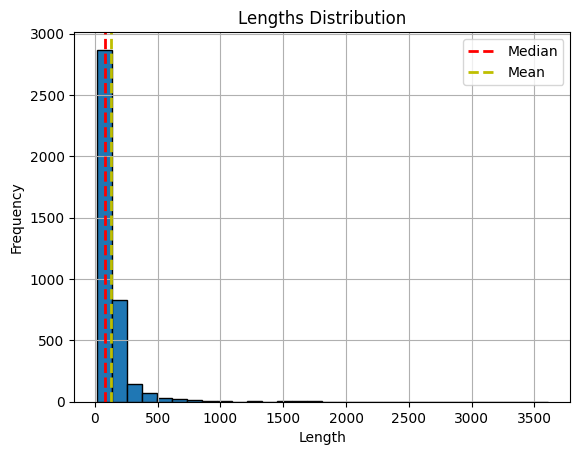

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
data = np.array(lengths)

plt.hist(data, bins=30, edgecolor='black')
plt.title('Lengths Distribution')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.grid(True)

median = np.median(data)
plt.axvline(median, color='r', linestyle='dashed', linewidth=2,label = 'Median')

mean = np.mean(data)
plt.axvline(mean, color='y', linestyle='dashed', linewidth=2, label='Mean')

plt.legend()
plt.show()


In [ ]:
import warnings
warnings.filterwarnings('ignore')

def bar_plot(data,feature):
    plt.figure(figsize=(10, 6))
    sns.countplot(x=feature, data=df, palette='viridis')
    plt.title(f'Distribution of {feature}')
    plt.xlabel('Label', fontsize=16)
    plt.ylabel('Count', fontsize=16)
    plt.xticks(fontsize=14, rotation=45)
    plt.yticks(fontsize=14)
    # counts = df[feature].value_counts().values
    # for i, v in enumerate(counts):
    #     plt.text(i, v + 1, str(v), ha='center',)

    plt.grid(True, axis='y')
    plt.show();


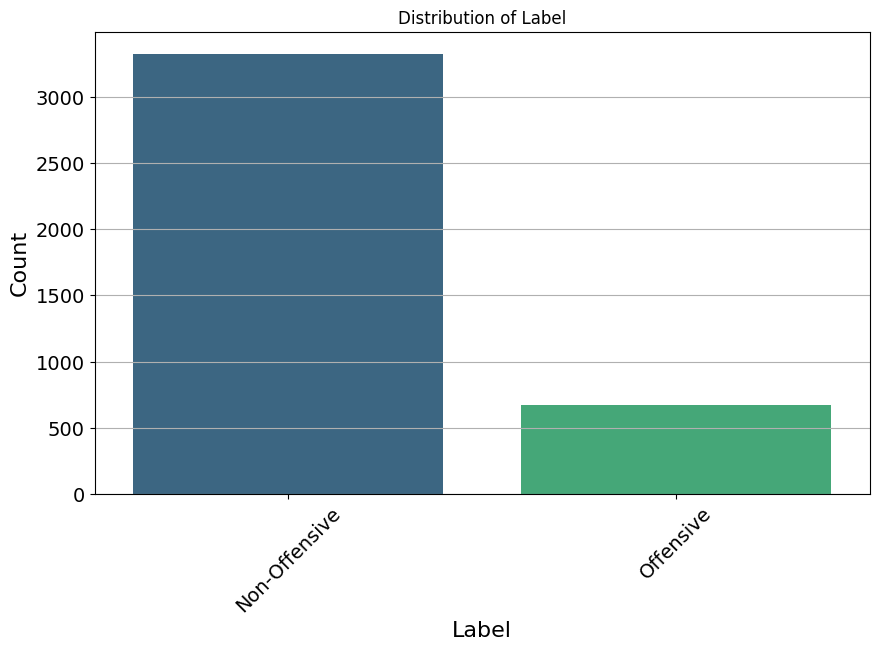

In [ ]:
bar_plot(df,'Label')

so imbalanced

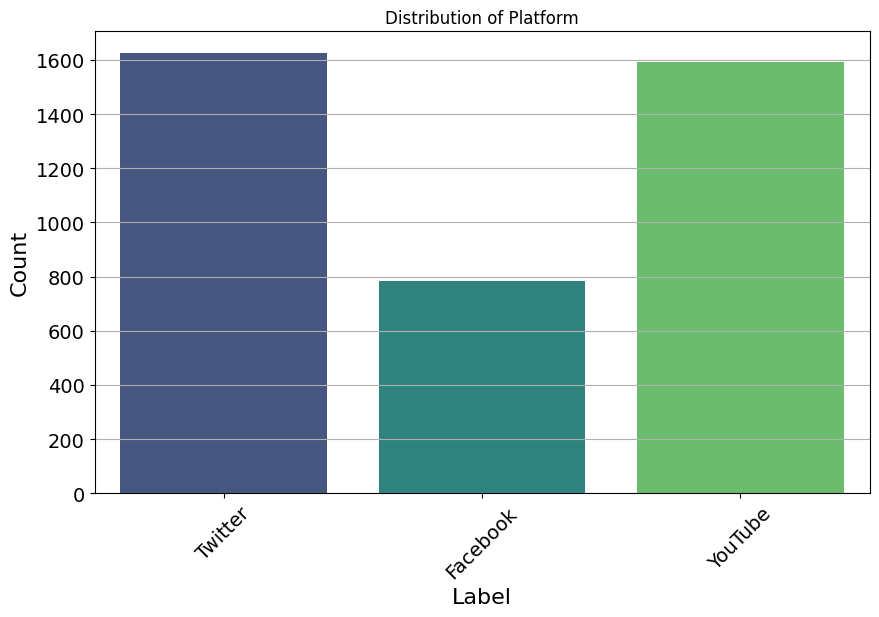

In [ ]:
bar_plot(df,'Platform')

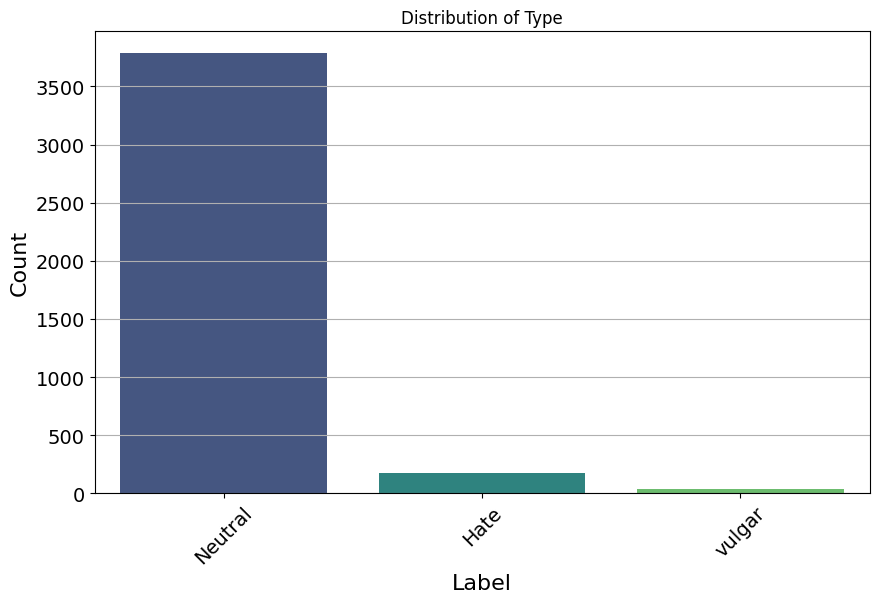

In [ ]:
bar_plot(df,'Type')

<Figure size 1000x600 with 0 Axes>

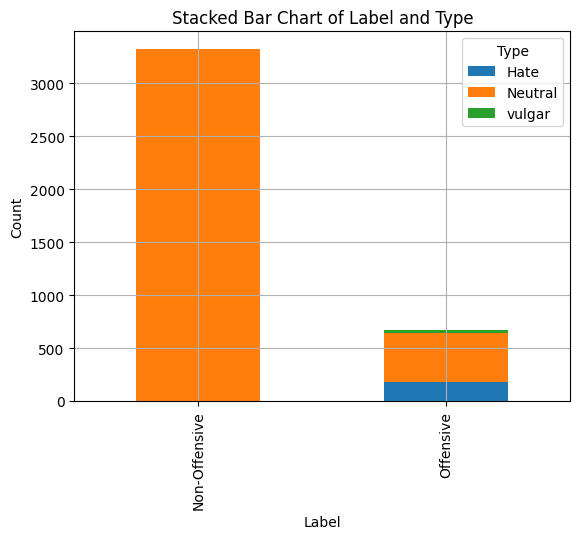

In [ ]:
def stacked_bar_chart(df, feature1, feature2):
    grouped = df.groupby([feature1, feature2]).size()

    stacked_df = grouped.unstack(fill_value=0)

    plt.figure(figsize=(10, 6))
    stacked_df.plot(kind='bar', stacked=True)
    plt.title('Stacked Bar Chart of ' + feature1 + ' and ' + feature2)
    plt.xlabel(feature1)
    plt.ylabel('Count')
    plt.grid(True, axis='y')
    plt.grid(True, axis='x')
    plt.show()

stacked_bar_chart(df,'Label', 'Type');

most of the offensive comments is actually Note HATE, hmm interesting

<Figure size 1000x600 with 0 Axes>

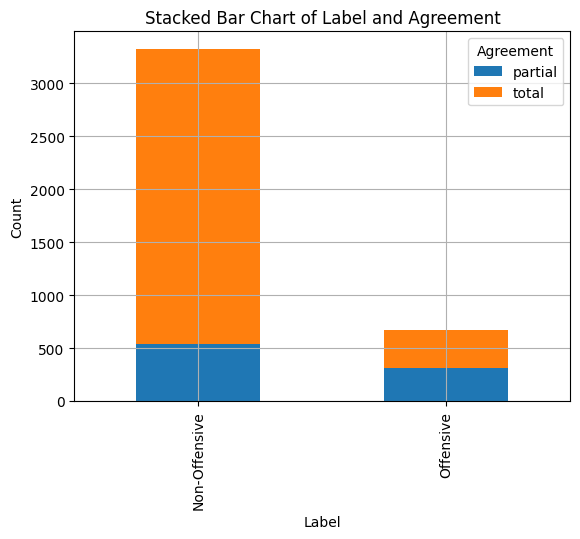

In [ ]:
stacked_bar_chart(df,'Label', 'Agreement');

acually in that way the data could be splitted into more than two categories.

<Figure size 1000x600 with 0 Axes>

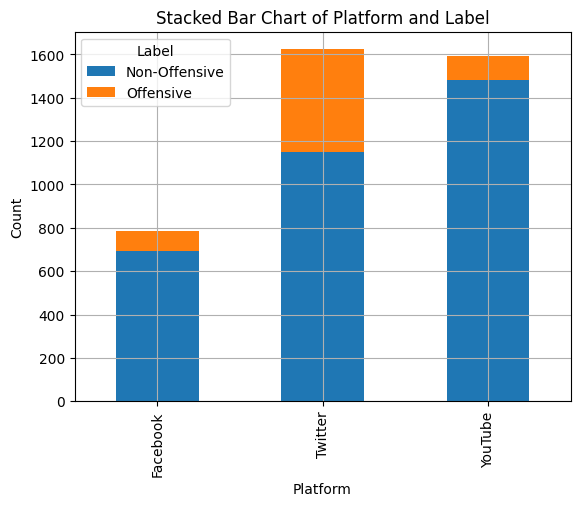

In [ ]:
stacked_bar_chart(df,'Platform', 'Label');

It seems that people on twitter is quit mean

In [ ]:
def display_random_examples(df, feature1, feature2, n = 2):
    combinations = df[[feature1, feature2]].drop_duplicates()

    examples = pd.DataFrame()

    for _, row in combinations.iterrows():
        matching_rows = df[(df[feature1] == row[feature1]) & (df[feature2] == row[feature2])]

        if len(matching_rows) >= n:
            selected_rows = matching_rows.sample(n)
        else:
            selected_rows = matching_rows

        examples = pd.concat([examples, selected_rows])

    examples.reset_index(drop=True, inplace=True)
    for _, row in examples.iterrows():
        label = row['Label']
        agr = row['Agreement']
        print(f'[{label}]')
        print(f'[{agr}]')
        print(row['Comment'])
        print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')


display_random_examples(df,'Label', 'Agreement')

[Non-Offensive]
[total]
@User.IDX والله ي انتم منقهرين من الامارات 😂😂😂 محاولت اخراج الموضوع بأفشل طريقة تقدرون عليها لاحول 😹😹😹 <url> 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
[Non-Offensive]
[total]
اول اشي لما تعملي حلقة تانية زي ما بتحكي يا ريت تستغني عن الموسيقى الي في الخلفية اللي بتخلي الواحد مش عارف يركز . مش مناسبة خالص. تاني اشي ولما يصير الدنيا كلها بنات ونتكاثر بدون ذكور ايش استفدنا يعني؟ انقرضوا الذكور خلص الاناث ينخمدوا وينقرضوا وراهم يريحونا خلي هالدنيا تخلص. والست لما بدها تتكاثر تقوم جايبة ذكر ايش رايك ساعتها نوئده؟ اه الوأد حل جميل للذكور ولا ايش رايك؟ الله يصبرنا ع العينات اللي بتلاقي حد يسمعلها ويروجلها 😏😑😑 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
[Offensive]
[partial]
لاحول ولاقوة الا بالله, فهمونا مين المغتصب الظالم الاكراد او الدواعش ؟؟؟؟؟ 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
[Offensive]
[partial]
@User.IDX قناة الجزيرة منبر لا منبر له في الفساد الاعلامي والأخلاقي ... وموضفو قناة الجزيرة هم اصلا من شياطين الأنس استعان فيهم حكام قطر لنشر الفتن بين الدول الاسلامية 
~~~~~~~~~~~~~~~~~~~~~~

In [ ]:
def get_unique_chars(df, feature):
    all_strings = ''.join(df[feature])
    unique_chars = set(all_strings)

    return list(unique_chars)
get_unique_chars(df,'Comment')[:10]

['ل', '😘', 'ﻉ', '⭕', 'ﺶ', '🍏', '☑', '😥', '۟', '–']

In [ ]:
import nltk
import re

def remove_non_arabic(df, feature):
    cleaned_comments = []

    for comment in df[feature]:
        # Remove non-Arabic characters and numbers
        cleaned_comment = re.sub(r'[^0-9\u0600-\u06ff\u0750-\u077f\ufb50-\ufbc1\ufbd3-\ufd3f\ufd50-\ufd8f\ufd50-\ufd8f\ufe70-\ufefc\uFDF0-\uFDFD-\u061c]+', ' ', comment)
        cleaned_comments.append(cleaned_comment)

    df[feature] = cleaned_comments
    return df

cleaned_df = remove_non_arabic(df, 'Comment')

In [ ]:
get_unique_chars(df,'Comment')[:10]

['ﺷ', 'ل', 'ﻊ', 'ﻀ', '٤', '9', 'م', 'ﻜ', 'ٱ', 'ﻉ']

decent

In [ ]:
df

,Id,Platform,Comment,Label,Agreement,NumOfJudgementUsed,Total_Judgement,Type
0,1,Twitter,في فترة الصغر والمراهقة يكون من الصعب تقبل تع...,Non-Offensive,total,3,3,Neutral
1,2,Facebook,ردا على معظم الردود أحب اوضحلكم ان عمليات زرع...,Non-Offensive,total,3,4,Neutral
2,3,Twitter,يجب ان تذكروا ان لكل سنة ثيم للحفل وهو نوع من...,Non-Offensive,total,3,5,Neutral
3,4,YouTube,بتعمل حلقة صغيرة عشان عندي امتحان بكرة ومتضيعل...,Non-Offensive,total,3,3,Neutral
4,5,YouTube,على طاري السطحيه مدري ليه تذكرت فيحان,Non-Offensive,total,3,3,Neutral
...,...,...,...,...,...,...,...,...
3995,3996,Facebook,والله ما اعرف ابكي على حالنا لي وصلنا ليه ام ا...,Non-Offensive,total,3,3,Neutral
3996,3997,YouTube,انا الحين ملخبط ذي كلها في البطاقه الائتمانية ...,Non-Offensive,total,3,4,Neutral
3997,3998,Facebook,أنا متأكد لو كان ستيفن هوكينج مسلما وثبتت تجار...,Non-Offensive,total,3,3,Neutral
3998,3999,YouTube,على فكرة في الدين حكم الاراهبين يطبق عليهم حكم...,Non-Offensive,partial,3,3,Neutral


In [ ]:
cleaned_df.to_csv('cleaned_comments.csv', index=False)